# 01 · Single-step × Iterative — modelos Instruct via HuggingFace

**Dissertação de mestrado (PPGCC/PUCRS).** Resultados da RQ1 (*a geração iterativa de
perguntas melhora o fact-checking?*) com os **modelos Instruct rodando pelo HuggingFace**
(rodadas `-hf`). **Estes são os números de referência daqui em diante** — é neste backend que
temos acesso às ativações internas, então é contra ele que os experimentos de SAE e steering
se comparam.

As tabelas seguem o formato do Seminário de Andamento (SA), com o **F1 da classe CONF**
acrescentado. A comparação com as rodadas do **Ollama** (as do SA e do artigo do ENIAC) fica
na §6.

**Setup comum às duas rodadas.** AVeriTeC dev (500 claims, 4 rótulos); DuckDuckGo → BM25
(top-10) → trechos de 300 tokens → *cross-encoder* `ms-marco-MiniLM-L-6-v2` (top-5 por query);
até 5 perguntas (single) ou 5 iterações (iterative); temperatura 0.

**O que muda entre as rodadas — duas coisas, não só o backend:**

| | rodadas `-hf` (este notebook) | rodadas Ollama (SA / ENIAC) |
|---|---|---|
| modelos | checkpoints *Instruct* do HuggingFace | tags padrão do Ollama (também *instruct*) |
| execução | `transformers`, 4-bit nf4 (bitsandbytes) | Ollama (GGUF quantizado) |
| checkpoints | `meta-llama/Llama-3.1-8B-Instruct`, `deepseek-ai/DeepSeek-R1-Distill-Llama-8B`, `Qwen/Qwen3-8B`, `google/gemma-3-4b-it`, `google/gemma-4-E4B-it` | `llama3.1:8b`, `deepseek-r1:8b`, `qwen3:8b`, `gemma3:4b`, `gemma4:e4b`, `ministral-3:8b`, `mistral:7b` |
| **parada do iterativo** | **o próprio LLM decide**, numa chamada estruturada `{stop, question}` (Algoritmo 2 do SA, linha 4) | heurística de confiança sobre as posturas (*stance*) das evidências |

> **Nota de nomenclatura.** Os modelos do Ollama também são versões *instruct*. A diferença
> entre as duas rodadas é o **backend e a quantização**, não o *instruction tuning*.


> ⚠️ **Atenção (28/09/2026) — defeito na regra de rótulo do pipeline.** Os números deste notebook
> usam a regra original do pipeline (`LLMVerdict.normalize`), que transforma em **REFUTED** muitas
> respostas que começam com **NOT ENOUGH EVIDENCE** (quando a explicação contém *"support or
> refute"*). Isso **infla a acurácia** e **subestima a abstenção**. A mesma regra foi usada nas rodadas
> do **Ollama (SA / ENIAC)** — confirmado pelos commits (§7). Estimativa corrigida para o Llama
> na **§7**. As conclusões qualitativas precisam ser revistas com a leitura correta.


## 1. Dados e como as métricas são calculadas

- **Predições:** `averitec_dev.jsonl` de cada rodada (1 linha por claim; conferido que a
  predição é a mesma do `metrics.jsonl`).
- **Custo (queries, tokens, latência):** `metrics.jsonl`, removendo duplicatas de retomadas
  (fica a **última** ocorrência de cada claim).
- **Métricas**, como no SA:
  - **Acurácia** sobre os 4 rótulos;
  - **macro-F1 = média de F1(SUP), F1(REF), F1(NEI)** — é a definição do SA (**sem CONF**).
    Mostramos também o F1 da CONF e um macro-F1 das 4 classes, separadamente;
  - **taxa de NEI** = fração de predições NEI;
  - **erro condicionado a não-NEI** = entre as predições SUP/REF/CONF, a fração errada.
- **Validação do cálculo:** aplicando este mesmo código às rodadas do Ollama, reproduzimos
  **exatamente** as Tabelas 1, 3 e 4 do SA (8 de 8 combinações modelo × método conferidas).
  A única diferença é o Gemma4 iterativo (ver §6).


In [1]:
import json, collections
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

OUT = "../old_method/corpora/averitec/outputs"
DIR = {"single": "averitec_original_pipeline", "iterative": "averitec_iterative_pipeline"}
L = {"SUPPORTED": "SUP", "REFUTED": "REF", "NOT ENOUGH EVIDENCE": "NEI", "CONFLICTING EVIDENCE/CHERRYPICKING": "CONF"}
CLS = ["SUP", "REF", "NEI", "CONF"]
HF = ["deepseek-r1-8b", "gemma3-4b", "gemma4-e4b", "llama3.1-8b", "qwen3-8b"]
OLLAMA = ["deepseek-r1-8b", "gemma3-4b", "gemma4-e4b", "llama3.1-8b", "ministral-3-8b", "mistral-7b", "qwen3-8b"]
NAME = {"deepseek-r1-8b": "DeepSeek-R1:8B", "gemma3-4b": "Gemma3:4B", "gemma4-e4b": "Gemma4-E4B",
        "llama3.1-8b": "LLaMA3.1:8B", "qwen3-8b": "Qwen3:8B", "ministral-3-8b": "Ministral3:8B", "mistral-7b": "Mistral:7B"}

def lab(s): return L.get((s or "").strip().upper(), "?")
def load(path):
    out = collections.OrderedDict()
    for line in open(path, encoding="utf-8"):
        try: r = json.loads(line)
        except Exception: continue          # linha corrompida (1 caso: DeepSeek-hf iterative)
        out[r["claim_id"]] = r               # retomadas: a última ocorrência vence
    return list(out.values())

def f1(pred, gold, c):
    tp = sum(p == c and g == c for p, g in zip(pred, gold)); fp = sum(p == c and g != c for p, g in zip(pred, gold))
    fn = sum(p != c and g == c for p, g in zip(pred, gold))
    pr = tp / (tp + fp) if tp + fp else 0.0; rc = tp / (tp + fn) if tp + fn else 0.0
    return 2 * pr * rc / (pr + rc) if pr + rc else 0.0

def evaluate(model, method, suffix):
    base = f"{OUT}/{DIR[method]}/{model}{suffix}"
    rows = load(f"{base}/averitec_dev.jsonl")
    pred = [lab(r["prediction"]) for r in rows]; gold = [lab(r["gold_label"]) for r in rows]
    F = {c: f1(pred, gold, c) for c in CLS}
    nn = [(p, g) for p, g in zip(pred, gold) if p != "NEI"]
    cost = load(f"{base}/metrics.jsonl")
    return {"model": model, "method": method, "n": len(rows), "n_cost": len(cost),
            "acc": np.mean([p == g for p, g in zip(pred, gold)]),
            "macroF1": np.mean([F["SUP"], F["REF"], F["NEI"]]), "macroF1_4": np.mean(list(F.values())),
            **{f"F1_{c}": F[c] for c in CLS},
            "nei_rate": np.mean([p == "NEI" for p in pred]),
            "err_nonNEI": np.mean([p != g for p, g in nn]) if nn else np.nan,
            "queries": np.mean([r["num_queries"] for r in cost]),
            "tokens": np.mean([r["total_tokens"] for r in cost]),
            "latency": np.mean([r["latency"] for r in cost]),
            "pred": pred, "gold": gold}

hf = {(m, k): evaluate(m, k, "-hf") for m in HF for k in DIR}
ol = {(m, k): evaluate(m, k, "") for m in OLLAMA for k in DIR}
for (m, k), r in hf.items():
    if r["n"] != 500 or r["n_cost"] != 500:
        print(f"atenção: {m}-hf {k}: {r['n']} predições, {r['n_cost']} linhas de custo")
print("rodadas carregadas:", len(hf), "HF |", len(ol), "Ollama")

atenção: deepseek-r1-8b-hf iterative: 500 predições, 498 linhas de custo
rodadas carregadas: 10 HF | 14 Ollama


## 2. Tabela 1 — desempenho geral (formato do SA + F1 da CONF)

**Como ler.** Uma linha por modelo × método. **Acc** = acurácia; **F1** = macro-F1 do SA (média
de SUP, REF e NEI); **F1 SUP/REF/NEI/CONF** = F1 de cada classe; **F1 (4 cl.)** = macro-F1
incluindo a CONF. A última linha de cada método é a média dos modelos. Em negrito (na leitura),
o melhor dos dois métodos por modelo.

In [2]:
def table1(res, models):
    rows = []
    for k, name in [("single", "Single-step"), ("iterative", "Iterative")]:
        for m in models:
            r = res[(m, k)]
            rows.append([NAME[m], name, r["acc"], r["macroF1"], r["F1_SUP"], r["F1_REF"], r["F1_NEI"], r["F1_CONF"], r["macroF1_4"]])
    df = pd.DataFrame(rows, columns=["Modelo", "Método", "Acc", "F1", "F1 SUP", "F1 REF", "F1 NEI", "F1 CONF", "F1 (4 cl.)"])
    avg = df.groupby("Método", sort=False).mean(numeric_only=True).reset_index(); avg.insert(0, "Modelo", "Média")
    df = pd.concat([df.sort_values(["Modelo", "Método"], key=lambda s: s.map({"Single-step": 0, "Iterative": 1}) if s.name == "Método" else s), avg])
    return df.set_index(["Modelo", "Método"]).round(3)

T1 = table1(hf, HF); T1

Acc     F1  F1 SUP  F1 REF  F1 NEI  F1 CONF  \
Modelo         Método                                                       
DeepSeek-R1:8B Single-step  0.460  0.438   0.538   0.599   0.177    0.000   
               Iterative    0.542  0.477   0.509   0.694   0.229    0.034   
Gemma3:4B      Single-step  0.592  0.326   0.175   0.742   0.062    0.000   
               Iterative    0.626  0.326   0.163   0.764   0.051    0.000   
Gemma4-E4B     Single-step  0.302  0.329   0.429   0.424   0.133    0.026   
               Iterative    0.394  0.401   0.514   0.521   0.167    0.111   
LLaMA3.1:8B    Single-step  0.436  0.395   0.440   0.608   0.138    0.000   
               Iterative    0.474  0.402   0.393   0.655   0.157    0.000   
Qwen3:8B       Single-step  0.428  0.441   0.584   0.551   0.188    0.000   
               Iterative    0.480  0.447   0.584   0.610   0.147    0.000   
Média          Single-step  0.444  0.386   0.433   0.585   0.140    0.005   
               Iterative    0.503  0.411   0.433   0.649   0.150    0.029   

                            F1 (4 cl.)  
Modelo         Método                   
DeepSeek-R1:8B Single-step       0.329  
               Iterative         0.367  
Gemma3:4B      Single-step       0.245  
               Iterative         0.245  
Gemma4-E4B     Single-step       0.253  
               Iterative         0.328  
LLaMA3.1:8B    Single-step       0.297  
               Iterative         0.301  
Qwen3:8B       Single-step       0.331  
               Iterative         0.335  
Média          Single-step       0.291  
               Iterative         0.315

👉 **Leitura.** O padrão qualitativo da RQ1 **se mantém** com os modelos HF: o iterativo tem
acurácia maior que o single-step **em todos os 5 modelos**, e o NEI continua sendo a classe
difícil. A CONF quase nunca é acertada (F1 ≈ 0 na maioria das células) — o Gemma4 iterativo
é a exceção, com F1 CONF = 0,111.

## 3. Tabela 2 — eficiência (queries e tokens por claim)

**Como ler.** **Queries (S)/(I)** = número médio de buscas por claim no single-step e no
iterativo; **Tokens (S→I)** = média de tokens consumidos por claim (prompt + geração, todas
as chamadas ao LLM). A latência é mostrada só como referência: depende da máquina e da carga.

In [3]:
rows = []
for m in HF:
    s, i = hf[(m, "single")], hf[(m, "iterative")]
    rows.append([NAME[m], s["queries"], i["queries"], f"{s['tokens']:.0f} → {i['tokens']:.0f}", s["latency"], i["latency"]])
T2 = pd.DataFrame(rows, columns=["Modelo", "Queries (S)", "Queries (I)", "Tokens (S→I)", "Latência s (S)", "Latência s (I)"])
avg = ["Média", T2["Queries (S)"].mean(), T2["Queries (I)"].mean(),
       f"{np.mean([hf[(m,'single')]['tokens'] for m in HF]):.0f} → {np.mean([hf[(m,'iterative')]['tokens'] for m in HF]):.0f}",
       T2["Latência s (S)"].mean(), T2["Latência s (I)"].mean()]
T2.loc[len(T2)] = avg
T2.set_index("Modelo").round(2)

,Queries (S),Queries (I),Tokens (S→I),Latência s (S),Latência s (I)
Modelo,,,,,
DeepSeek-R1:8B,5.03,3.15,20540 → 42614,141.99,275.67
Gemma3:4B,4.96,4.66,16823 → 44388,50.11,135.71
Gemma4-E4B,4.38,4.29,16043 → 40997,40.67,111.34
LLaMA3.1:8B,5.00,4.76,17074 → 44949,38.73,115.73
Qwen3:8B,5.00,2.87,17361 → 34693,48.11,110.72
Média,4.87,3.95,17568 → 41528,63.92,149.83


👉 **Leitura — diferença importante em relação ao SA.** Na rodada HF, o iterativo **quase não
reduz o número de queries** (média 4,87 → 3,95; Llama 5,00 → 4,76; Gemma3 4,96 → 4,66), e o
consumo de tokens **mais que dobra** (≈17,6k → 41,5k). No SA, a redução era de 4,96 → 2,38, com
tokens subindo pouco (14,6k → 16,7k). O ganho de **eficiência** do "Less is More" **não se
replica** aqui, a não ser parcialmente no DeepSeek (5,03 → 3,15) e no Qwen3 (5,00 → 2,87).

A causa mais provável é a **regra de parada**: nas rodadas HF é o próprio LLM que decide parar
(Algoritmo 2), e a maioria dos modelos raramente decide parar antes do limite de 5; na rodada
do Ollama, a parada vinha de uma heurística de confiança. O ganho de **acurácia** do iterativo,
por outro lado, se mantém (Tabela 1).

## 4. Tabelas 3 e 4 — abstenção (taxa de NEI) e confiabilidade (erro fora de NEI)

**Como ler.** *Tabela 3:* fração das predições que são NEI em cada método e a variação
(Δ = iterativo − single). *Tabela 4:* entre as predições que **não** são NEI (o modelo decidiu),
a fração errada — mede se abster menos custou mais erros.

In [4]:
def delta_table(res, models, key):
    rows = [[NAME[m], res[(m, "single")][key], res[(m, "iterative")][key]] for m in models]
    df = pd.DataFrame(rows, columns=["Modelo", "Single", "Iterative"]); df["Δ"] = df["Iterative"] - df["Single"]
    df.loc[len(df)] = ["Média", df["Single"].mean(), df["Iterative"].mean(), df["Δ"].mean()]
    return df.set_index("Modelo").round(3)

T3 = delta_table(hf, HF, "nei_rate"); T4 = delta_table(hf, HF, "err_nonNEI")
print("Tabela 3 — taxa de NEI"); display(T3)
print("Tabela 4 — erro condicionado a predições não-NEI"); display(T4)

Tabela 3 — taxa de NEI


,Single,Iterative,Δ
Modelo,,,
DeepSeek-R1:8B,0.404,0.244,-0.160
Gemma3:4B,0.060,0.008,-0.052
Gemma4-E4B,0.562,0.432,-0.130
LLaMA3.1:8B,0.422,0.364,-0.058
Qwen3:8B,0.526,0.366,-0.160
Média,0.395,0.283,-0.112


Tabela 4 — erro condicionado a predições não-NEI


,Single,Iterative,Δ
Modelo,,,
DeepSeek-R1:8B,0.299,0.331,0.032
Gemma3:4B,0.374,0.371,-0.004
Gemma4-E4B,0.406,0.380,-0.026
LLaMA3.1:8B,0.304,0.308,0.004
Qwen3:8B,0.215,0.293,0.078
Média,0.320,0.337,0.017


👉 **Leitura.** O iterativo **reduz a abstenção em todos os modelos**, como no SA. Duas
observações específicas desta rodada:
- a abstenção dos modelos HF no **single-step** é alta (0,40–0,56 na maioria), e o gold tem
  só 35 NEI em 500 (7%) — a **super-abstenção** que motiva o estágio 2 (steering);
- o Gemma3 quase nunca abstém em nenhum dos dois backends (0,06 → 0,008).

## 5. Distribuição das predições e matrizes de confusão

**Como ler.** *Tabela:* quantas vezes cada rótulo foi predito (e, na última linha, a
distribuição do gold). *Figura:* uma matriz por modelo × método; linhas = rótulo verdadeiro,
colunas = rótulo predito, e cada célula é o **número de claims** (as linhas somam o total de
cada classe no gold: SUP 122, REF 305, NEI 35, CONF 38). A diagonal é o acerto; a coluna
**NEI** mostra quantos claims de cada classe verdadeira viraram abstenção. A cor é relativa ao
maior valor de cada matriz.

In [5]:
rows = []
for m in HF:
    for k in DIR:
        c = collections.Counter(hf[(m, k)]["pred"]); rows.append([NAME[m], k] + [c.get(x, 0) for x in CLS + ["?"]])
g = collections.Counter(hf[(HF[0], "single")]["gold"]); rows.append(["gold", "—"] + [g.get(x, 0) for x in CLS + ["?"]])
pd.DataFrame(rows, columns=["Modelo", "Método"] + CLS + ["não-parseado"]).set_index(["Modelo", "Método"])

SUP  REF  NEI  CONF  não-parseado
Modelo         Método                                      
DeepSeek-R1:8B single      86  206  202     6             0
               iterative   98  260  122    20             0
Gemma3:4B      single      15  455   30     0             0
               iterative   13  483    4     0             0
Gemma4-E4B     single      74  105  281    40             0
               iterative   92  140  216    52             0
LLaMA3.1:8B    single      69  218  211     2             0
               iterative   61  257  182     0             0
Qwen3:8B       single      63  174  263     0             0
               iterative  104  213  183     0             0
gold           —          122  305   35    38             0

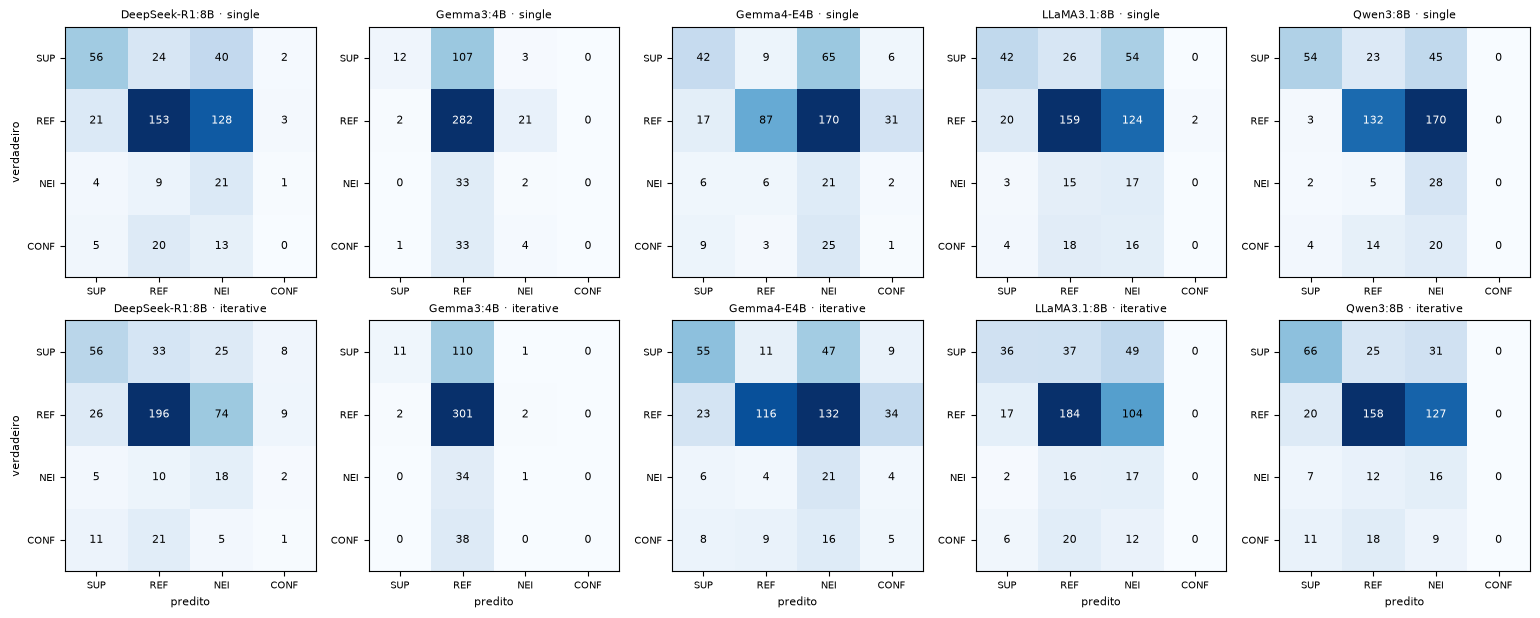

In [6]:
def cm(pred, gold):
    M = np.zeros((4, 4))
    for p, g in zip(pred, gold):
        if p in CLS: M[CLS.index(g), CLS.index(p)] += 1
    return M

fig, axes = plt.subplots(2, len(HF), figsize=(3.1 * len(HF), 6.2))
for j, m in enumerate(HF):
    for i, k in enumerate(["single", "iterative"]):
        ax = axes[i, j]; M = cm(hf[(m, k)]["pred"], hf[(m, k)]["gold"])
        ax.imshow(M, cmap="Blues", vmin=0, vmax=M.max())
        for a in range(4):
            for b in range(4):
                ax.text(b, a, f"{int(M[a,b])}", ha="center", va="center", fontsize=8, color="white" if M[a, b] > .6 * M.max() else "black")
        ax.set_xticks(range(4)); ax.set_xticklabels(CLS, fontsize=7); ax.set_yticks(range(4)); ax.set_yticklabels(CLS, fontsize=7)
        ax.set_title(f"{NAME[m]} · {k}", fontsize=8)
        if j == 0: ax.set_ylabel("verdadeiro", fontsize=8)
        if i == 1: ax.set_xlabel("predito", fontsize=8)
plt.tight_layout(); plt.show()

## 6. Comparação: HuggingFace (Instruct, 4-bit nf4) × Ollama (SA / ENIAC)

Os números do SA e do artigo do ENIAC vêm das rodadas do **Ollama**. Refizemos as mesmas
rodadas no **HuggingFace** porque é o único backend que dá acesso às ativações internas (o
Ollama não expõe *hidden states*). As duas rodadas **não coincidem** numericamente.

**Como ler.** Para cada modelo presente nos dois backends: acurácia e taxa de NEI em cada
backend e a diferença (Δ = HF − Ollama). Ministral e Mistral só existem no Ollama.

**Três ressalvas sobre os dados do Ollama:**
- **Gemma4 iterativo (Ollama) está incompleto:** 288 de 500 claims. O SA reporta um trecho
  parcial ainda menor (acc 0,480, NEI 0,400); aqui usamos os 288 disponíveis — **não é
  comparável** aos 500 do HF.
- Nas rodadas HF, o DeepSeek iterativo tem 2 claims (278 e 279) sem linha de custo em
  `metrics.jsonl`; as predições dos 500 existem no `averitec_dev.jsonl`.
- **Não sabemos se as rodadas HF reusaram as páginas em cache ou buscaram de novo no
  DuckDuckGo.** Se buscaram de novo, a evidência também muda entre os backends, não só o LLM.

In [7]:
rows = []
for m in HF:
    for k in ["single", "iterative"]:
        o, h = ol[(m, k)], hf[(m, k)]
        rows.append([NAME[m], k, o["n"], o["acc"], h["acc"], h["acc"] - o["acc"], o["nei_rate"], h["nei_rate"], h["nei_rate"] - o["nei_rate"],
                     o["macroF1"], h["macroF1"]])
C = pd.DataFrame(rows, columns=["Modelo", "Método", "n Ollama", "Acc Ollama", "Acc HF", "Δ Acc",
                                "NEI Ollama", "NEI HF", "Δ NEI", "F1 Ollama", "F1 HF"])
C.set_index(["Modelo", "Método"]).round(3)

n Ollama  Acc Ollama  Acc HF  Δ Acc  NEI Ollama  \
Modelo         Método                                                       
DeepSeek-R1:8B single          500       0.424   0.460  0.036       0.520   
               iterative       500       0.564   0.542 -0.022       0.270   
Gemma3:4B      single          500       0.598   0.592 -0.006       0.060   
               iterative       500       0.616   0.626  0.010       0.022   
Gemma4-E4B     single          500       0.372   0.302 -0.070       0.586   
               iterative       288       0.500   0.394 -0.106       0.375   
LLaMA3.1:8B    single          500       0.502   0.436 -0.066       0.300   
               iterative       500       0.608   0.474 -0.134       0.144   
Qwen3:8B       single          500       0.378   0.428  0.050       0.606   
               iterative       500       0.546   0.480 -0.066       0.320   

                          NEI HF  Δ NEI  F1 Ollama  F1 HF  
Modelo         Método                                      
DeepSeek-R1:8B single      0.404 -0.116      0.405  0.438  
               iterative   0.244 -0.026      0.477  0.477  
Gemma3:4B      single      0.060  0.000      0.342  0.326  
               iterative   0.008 -0.014      0.337  0.326  
Gemma4-E4B     single      0.562 -0.024      0.369  0.329  
               iterative   0.432  0.057      0.475  0.401  
LLaMA3.1:8B    single      0.422  0.122      0.405  0.395  
               iterative   0.364  0.220      0.480  0.402  
Qwen3:8B       single      0.526 -0.080      0.380  0.441  
               iterative   0.366  0.046      0.496  0.447

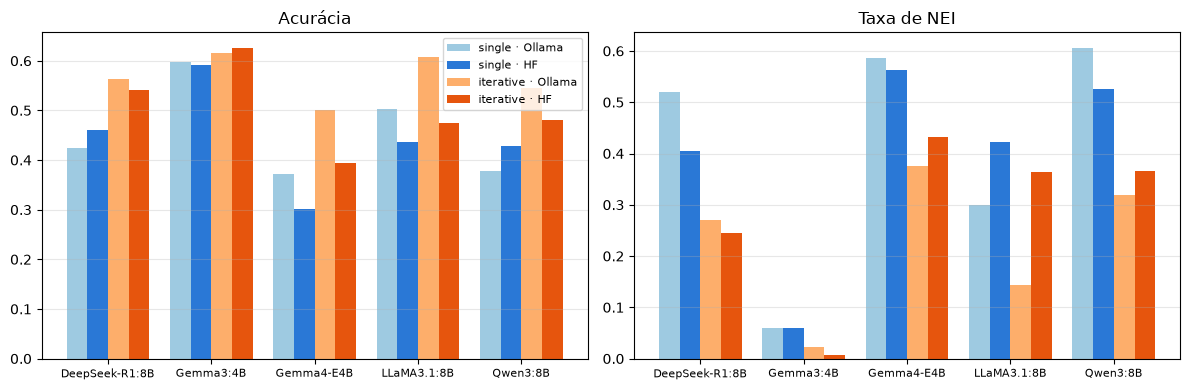

In [8]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
x = np.arange(len(HF)); w = 0.2
for off, (k, back, res, col) in zip([-1.5, -.5, .5, 1.5], [("single", "Ollama", ol, "#9ecae1"), ("single", "HF", hf, "#2a78d6"),
                                                         ("iterative", "Ollama", ol, "#fdae6b"), ("iterative", "HF", hf, "#e6550d")]):
    a1.bar(x + off * w, [res[(m, k)]["acc"] for m in HF], w, color=col, label=f"{k} · {back}")
    a2.bar(x + off * w, [res[(m, k)]["nei_rate"] for m in HF], w, color=col, label=f"{k} · {back}")
for a, t in [(a1, "Acurácia"), (a2, "Taxa de NEI")]:
    a.set_xticks(x); a.set_xticklabels([NAME[m] for m in HF], fontsize=8); a.set_title(t); a.grid(axis="y", alpha=.3)
a1.legend(fontsize=8); plt.tight_layout(); plt.show()

**Como ler este gráfico.** Cada grupo de barras é um modelo. Tons **azuis** = single-step,
tons **laranja** = iterativo; a cor **clara** é o Ollama e a **escura** é o HF. *Esquerda:*
acurácia; *direita:* taxa de NEI. Nota: o Gemma4 iterativo do Ollama tem só 288 claims.

In [9]:
rows = [[NAME[m], ol[(m, "single")]["acc"], ol[(m, "iterative")]["acc"], ol[(m, "single")]["nei_rate"], ol[(m, "iterative")]["nei_rate"], ol[(m, "iterative")]["n"]]
        for m in OLLAMA]
print("Referência: rodadas do Ollama (as do SA), inclusive os modelos sem versão HF")
pd.DataFrame(rows, columns=["Modelo", "Acc S", "Acc I", "NEI S", "NEI I", "n (I)"]).set_index("Modelo").round(3)

Referência: rodadas do Ollama (as do SA), inclusive os modelos sem versão HF


,Acc S,Acc I,NEI S,NEI I,n (I)
Modelo,,,,,
DeepSeek-R1:8B,0.424,0.564,0.520,0.270,500
Gemma3:4B,0.598,0.616,0.060,0.022,500
Gemma4-E4B,0.372,0.500,0.586,0.375,288
LLaMA3.1:8B,0.502,0.608,0.300,0.144,500
Ministral3:8B,0.402,0.614,0.472,0.170,500
Mistral:7B,0.262,0.264,0.718,0.700,500
Qwen3:8B,0.378,0.546,0.606,0.320,500


👉 **Leitura.**
- **A conclusão qualitativa da RQ1 é a mesma nos dois backends:** iterativo > single em
  acurácia, e a taxa de NEI cai do single para o iterativo, em todos os modelos.
- **Os números absolutos mudam.** Em DeepSeek e Gemma3 as rodadas ficam próximas; em Llama,
  Qwen3 e Gemma4 o HF diverge (no Llama o iterativo HF fica ~13 pontos abaixo do Ollama). Há
  duas causas combinadas: (i) a troca de backend e quantização (GGUF × nf4) → gerações
  diferentes → perguntas diferentes → evidência diferente → vereditos diferentes; (ii) no
  **iterativo**, a regra de parada mudou (o LLM decide × heurística), o que muda quantas
  buscas são feitas (§3). Não é erro de métrica — o mesmo código reproduz o SA com os dados do
  Ollama.
- **O ganho de acurácia do iterativo é menor no HF** (média +5,9 pontos nos 5 modelos HF, contra +9,2 na média dos 6 modelos do SA), e
  o ganho de eficiência praticamente some (§3).
- **Decisão do projeto:** os números **HF** são a referência daqui para frente (é onde temos
  as ativações); os do Ollama ficam como o registro do ENIAC.

## 7. Defeito na regra de rótulo do pipeline (achado em 28/09/2026)

**O que é.** O pipeline extrai o rótulo da resposta do LLM com `LLMVerdict.normalize`
(`shared/modules/verdict/llm_verdict.py`), que procura as palavras **nesta ordem**: "REFUTE" ou
"FALSE" **em qualquer ponto do texto** → REF; só depois "SUPPORT", "CONFLICT" e "NOT ENOUGH". Os
modelos costumam responder o rótulo e depois uma explicação, e a explicação típica de uma abstenção é:

> *"**NOT ENOUGH EVIDENCE**\n\nThe evidence provided does not contain any direct evidence to support
> or **refute** the claim…"*

→ registrada como **REFUTED**. Como 61% do gold é REF, boa parte desses erros de leitura **viram
acertos**: a acurácia fica inflada e a taxa de NEI, subestimada.

**Onde está o código e qual versão cada rodada usou (verificado em 28/09/2026).** O código do pipeline
**não está** no projeto atual (`old_method/` guarda só as saídas). Ele existe (i) na cópia antiga do
projeto em `/mnt/d/Projetos WSL/mestrado/`, que ainda tem o histórico Git, e (ii) no repositório público
`github.com/lucasfrag/iterative-question-generation`. Cada rodada gravou o commit do código no
`config.json`:

| rodadas | commit | arquivo | `normalize` |
|---|---|---|---|
| HF (este notebook) | `dc19749` (03/09/2026) | `iterative-question-generation/modules/verdict/llm_verdict.py`, linhas 85–104 | a regra descrita acima (arquivo **idêntico** ao lido) |
| Ollama (SA / ENIAC) | `53829d5` e `809230a` | `modules/verdict/llm_verdict.py` (repositório público), linhas 85–104 | **a mesma regra** |

Nos três commits, `pipeline/pipeline_factory.py` usa `LLMVerdict` no Single-step (linha 48) e no
Iterative (linha 82). Ou seja: **os números do SA e do artigo do ENIAC também foram extraídos com essa
regra**. O que não dá para medir é o **tamanho** do efeito no Ollama, porque aqueles JSONL não guardam o
texto das respostas (e o formato das respostas do Ollama pode ser diferente do HF).

**Como foi descoberto.** No experimento de steering (`03-steering-sae-v3.ipynb`, §3.1), reexecutamos o
passo de veredito do pipeline do Llama com o **mesmo prompt** (idêntico byte a byte) e guardando o
**texto completo** das respostas. Esse *replay* reproduz as predições do pipeline em **99%** dos claims
(lidas com a mesma regra) — então serve para estimar o que o pipeline teria dado com a leitura correta
(**o 1º rótulo que o modelo escreve**).

**Como ler a tabela.** Llama-3.1-8B HF, 500 claims. "Regra do pipeline" = como está na Tabela 1;
"1º rótulo" = leitura correta, estimada pelo replay. A linha do Iterative aparece quando o replay dele
estiver pronto.

In [10]:
import os, sys
from fcsae.steering.factcheck_sae import first_label, normalize
RP = "../results/v3_llama/steer_sae"
rows = []
for k, name in [("single", "Single-step"), ("iterative", "Iterative")]:
    f = f"{RP}/{k}__none__b+0.00.json"
    if not os.path.exists(f):
        rows.append([name] + [np.nan] * 7); continue
    r = json.load(open(f, encoding="utf-8")); g = r["gold"]
    rule = [normalize(x) for x in r["raw"]]; fl = [first_label(x) for x in r["raw"]]
    agree = np.mean([a == b for a, b in zip(rule, r["pipeline_pred"])])
    acc = lambda P: np.mean([p == q for p, q in zip(P, g)]); nei = lambda P: np.mean([p == "NEI" for p in P])
    rows.append([name, agree, acc(r["pipeline_pred"]), acc(fl), nei(r["pipeline_pred"]), nei(fl),
                 sum(a == "NEI" and b == "REF" for a, b in zip(fl, rule)),
                 sum(a == "NEI" and b == "REF" and q == "REF" for a, b, q in zip(fl, rule, g))])
pd.DataFrame(rows, columns=["Llama HF", "replay = pipeline", "Acc (regra do pipeline)", "Acc (1º rótulo)",
                            "NEI (regra do pipeline)", "NEI (1º rótulo)", "NEI lidos como REF", "…desses, gold REF"]).set_index("Llama HF").round(3)

,replay = pipeline,Acc (regra do pipeline),Acc (1º rótulo),NEI (regra do pipeline),NEI (1º rótulo),NEI lidos como REF,"…desses, gold REF"
Llama HF,,,,,,,
Single-step,0.990,0.436,0.36,0.422,0.620,76,45
Iterative,0.988,0.474,0.42,0.364,0.494,49,31


👉 **Leitura.** No Llama Single-step, a acurácia cai de **0,436 para ~0,36** e a abstenção sobe de
**~0,42 para ~0,62** quando se lê o rótulo que o modelo de fato escreveu.

**O que isto significa para a RQ1 (a revisar):**
- os números absolutos das Tabelas 1, 3 e 4 deste notebook estão **enviesados a favor de REF**;
- a comparação Single × Iterative pode mudar (se o iterativo escreve explicações diferentes, o viés
  de leitura é diferente nos dois);
- **as rodadas do Ollama (SA / ENIAC) usaram a mesma regra** (confirmado pelos commits, acima), mas o
  **tamanho** do viés nelas não pode ser medido: os JSONL guardam só a predição final, não o texto da
  resposta — fica registrado como limitação.

**Feito (30/09/2026):** o passo de veredito dos outros 4 modelos HF foi re-rodado da mesma forma — ver §8.

## 8. Resultados corrigidos — todos os modelos HF (replay do veredito, 30/09/2026)

**O que foi feito.** Para cada um dos 5 modelos e cada método, re-rodamos **só o último passo** do
pipeline — o veredito — com **exatamente o mesmo prompt**: a mesma claim e a **mesma evidência** que o
pipeline recuperou (lidas do `averitec_dev.jsonl` de cada rodada), o mesmo checkpoint HF em 4 bits
nf4, geração *greedy*, até 1.536 tokens, `enable_thinking=False` e remoção do `<think>` — as mesmas
configurações de `old_method/shared/llm/hf_llm.py` e `shared/config.py` (commit `dc19749`). **A busca de
evidências e a geração de perguntas não foram refeitas.** Desta vez o **texto completo** da resposta foi
guardado, e o rótulo é lido como na §7: o **1º rótulo que o modelo escreve**, em maiúsculas e por
extenso, ignorando enumerações das opções (`first_label` em `fcsae/steering/factcheck_sae.py`).

- Llama: `results/v3_llama/steer_sae/{single,iterative}__none__b+0.00.json` (o α = 0 do steering);
- demais: `results/replay/<modelo>-hf/{single,iterative}__none__b+0.00.json`
  (`python -m fcsae.steering.factcheck_sae --replay <tag>`; fila em `scripts/run_replay_all.sh`).

**O custo (queries, tokens) não muda** — vem da busca, que não foi refeita — então a Tabela 2 continua
válida. Mudam as Tabelas 1, 3 e 4.

### 8.1 O replay reproduz o pipeline?

**Como ler.** Para cada modelo e método: **concordância** = fração dos 500 claims em que o replay, lido
com a **mesma regra do pipeline** (`normalize`), dá o mesmo rótulo que o pipeline gravou. Mede se o
replay regerou as mesmas respostas. As divergências vêm de respostas longas em que a geração tomou outro
caminho (em 4 bits, pequenas diferenças numéricas podem mudar o argmax num token e, daí em diante, o
texto); nesses claims, o rótulo corrigido é o do replay.

In [11]:
from fcsae.steering.factcheck_sae import first_label, normalize
RPF = {m: f"../results/replay/{m}-hf" for m in HF}; RPF["llama3.1-8b"] = "../results/v3_llama/steer_sae"

def metrics_from(pred, gold):
    F = {c: f1(pred, gold, c) for c in CLS}
    nn = [(p, g) for p, g in zip(pred, gold) if p != "NEI"]
    return {"acc": np.mean([p == g for p, g in zip(pred, gold)]),
            "macroF1": np.mean([F["SUP"], F["REF"], F["NEI"]]), "macroF1_4": np.mean(list(F.values())),
            **{f"F1_{c}": F[c] for c in CLS}, "nei_rate": np.mean([p == "NEI" for p in pred]),
            "err_nonNEI": np.mean([p != g for p, g in nn]) if nn else np.nan, "pred": pred, "gold": gold, "n": len(pred)}

fx, rows = {}, []
for m in HF:
    for k in DIR:
        r = json.load(open(f"{RPF[m]}/{k}__none__b+0.00.json", encoding="utf-8"))
        rule = [normalize(x) for x in r["raw"]]
        agree = np.mean([a == b for a, b in zip(rule, r["pipeline_pred"])])
        fx[(m, k)] = {**metrics_from([first_label(x) for x in r["raw"]], r["gold"]), "ids": r["ids"], "pipe": r["pipeline_pred"]}
        rows.append([NAME[m], k, len(r["raw"]), agree, sum(a != b for a, b in zip(rule, r["pipeline_pred"]))])
pd.DataFrame(rows, columns=["Modelo", "Método", "claims", "concordância", "divergentes"]).set_index(["Modelo", "Método"]).round(3)

claims  concordância  divergentes
Modelo         Método                                      
DeepSeek-R1:8B single        500         0.970           15
               iterative     500         0.972           14
Gemma3:4B      single        500         0.998            1
               iterative     500         0.998            1
Gemma4-E4B     single        500         0.998            1
               iterative     500         0.998            1
LLaMA3.1:8B    single        500         0.990            5
               iterative     500         0.988            6
Qwen3:8B       single        500         0.996            2
               iterative     500         0.998            1

### 8.2 Tabela 1 corrigida — desempenho geral

**Como ler.** Mesmo formato da Tabela 1 (§2), com o rótulo lido corretamente. A 2ª tabela mostra a
**diferença** para a Tabela 1 original (corrigida − original): negativo = a regra do pipeline inflava a
métrica.

In [12]:
T1c = table1(fx, HF); display(T1c)
print("diferença para a Tabela 1 original (corrigida − original):")
(T1c - T1).round(3)

Acc     F1  F1 SUP  F1 REF  F1 NEI  F1 CONF  \
Modelo         Método                                                       
DeepSeek-R1:8B Single-step  0.448  0.428   0.520   0.599   0.164    0.085   
               Iterative    0.536  0.481   0.545   0.687   0.211    0.037   
Gemma3:4B      Single-step  0.590  0.325   0.175   0.740   0.061    0.000   
               Iterative    0.624  0.321   0.149   0.763   0.051    0.000   
Gemma4-E4B     Single-step  0.304  0.330   0.429   0.428   0.133    0.026   
               Iterative    0.396  0.402   0.514   0.525   0.168    0.111   
LLaMA3.1:8B    Single-step  0.360  0.379   0.480   0.502   0.157    0.000   
               Iterative    0.420  0.394   0.430   0.594   0.156    0.000   
Qwen3:8B       Single-step  0.400  0.424   0.573   0.512   0.188    0.000   
               Iterative    0.452  0.434   0.574   0.581   0.148    0.000   
Média          Single-step  0.420  0.377   0.435   0.556   0.140    0.022   
               Iterative    0.486  0.406   0.442   0.630   0.147    0.030   

                            F1 (4 cl.)  
Modelo         Método                   
DeepSeek-R1:8B Single-step       0.342  
               Iterative         0.370  
Gemma3:4B      Single-step       0.244  
               Iterative         0.241  
Gemma4-E4B     Single-step       0.254  
               Iterative         0.329  
LLaMA3.1:8B    Single-step       0.285  
               Iterative         0.295  
Qwen3:8B       Single-step       0.318  
               Iterative         0.326  
Média          Single-step       0.289  
               Iterative         0.312

diferença para a Tabela 1 original (corrigida − original):


Acc     F1  F1 SUP  F1 REF  F1 NEI  F1 CONF  \
Modelo         Método                                                       
DeepSeek-R1:8B Single-step -0.012 -0.010  -0.018   0.000  -0.013    0.085   
               Iterative   -0.006  0.004   0.036  -0.007  -0.018    0.003   
Gemma3:4B      Single-step -0.002 -0.001   0.000  -0.002  -0.001    0.000   
               Iterative   -0.002 -0.005  -0.014  -0.001   0.000    0.000   
Gemma4-E4B     Single-step  0.002  0.001   0.000   0.004   0.000    0.000   
               Iterative    0.002  0.001   0.000   0.004   0.001    0.000   
LLaMA3.1:8B    Single-step -0.076 -0.016   0.040  -0.106   0.019    0.000   
               Iterative   -0.054 -0.008   0.037  -0.061  -0.001    0.000   
Qwen3:8B       Single-step -0.028 -0.017  -0.011  -0.039   0.000    0.000   
               Iterative   -0.028 -0.013  -0.010  -0.029   0.001    0.000   
Média          Single-step -0.024 -0.009   0.002  -0.029   0.000    0.017   
               Iterative   -0.017 -0.005   0.009  -0.019  -0.003    0.001   

                            F1 (4 cl.)  
Modelo         Método                   
DeepSeek-R1:8B Single-step       0.013  
               Iterative         0.003  
Gemma3:4B      Single-step      -0.001  
               Iterative        -0.004  
Gemma4-E4B     Single-step       0.001  
               Iterative         0.001  
LLaMA3.1:8B    Single-step      -0.012  
               Iterative        -0.006  
Qwen3:8B       Single-step      -0.013  
               Iterative        -0.009  
Média          Single-step      -0.002  
               Iterative        -0.003

### 8.3 Tabelas 3 e 4 corrigidas — abstenção e erro fora de NEI

**Como ler.** Mesmo formato das Tabelas 3 e 4 (§4). *Tabela 3:* taxa de NEI e Δ = iterativo − single.
*Tabela 4:* entre as predições que não são NEI, a fração errada.

In [13]:
T3c = delta_table(fx, HF, "nei_rate"); T4c = delta_table(fx, HF, "err_nonNEI")
print("Tabela 3 corrigida — taxa de NEI"); display(T3c)
print("Tabela 4 corrigida — erro condicionado a predições não-NEI"); display(T4c)

Tabela 3 corrigida — taxa de NEI


,Single,Iterative,Δ
Modelo,,,
DeepSeek-R1:8B,0.442,0.290,-0.152
Gemma3:4B,0.062,0.008,-0.054
Gemma4-E4B,0.560,0.430,-0.130
LLaMA3.1:8B,0.620,0.494,-0.126
Qwen3:8B,0.570,0.416,-0.154
Média,0.451,0.328,-0.123


Tabela 4 corrigida — erro condicionado a predições não-NEI


,Single,Iterative,Δ
Modelo,,,
DeepSeek-R1:8B,0.272,0.299,0.026
Gemma3:4B,0.375,0.373,-0.002
Gemma4-E4B,0.405,0.379,-0.026
LLaMA3.1:8B,0.195,0.257,0.062
Qwen3:8B,0.209,0.288,0.078
Média,0.291,0.319,0.028


### 8.4 A conclusão da RQ1 muda? — Single × Iterative, por modelo

**Como ler.** Para cada modelo: a acurácia do Single e do Iterative com a regra original (Tabela 1) e
com a leitura correta, e o **teste de McNemar exato** entre os dois métodos na leitura correta (mesmos
500 claims; só contam os claims em que exatamente um dos dois acerta — Dietterich, 1998). **▲** = o
iterativo é melhor com p < 0,05; **=** = sem diferença significativa; **▼** = o iterativo é pior.

In [14]:
from scipy.stats import binomtest
from IPython.display import Markdown, display

def mcnemar(pa, pb, gold):
    b = sum((x == g) and (y != g) for x, y, g in zip(pa, pb, gold)); c = sum((x != g) and (y == g) for x, y, g in zip(pa, pb, gold))
    return binomtest(min(b, c), b + c, 0.5).pvalue if b + c else 1.0

rows, lines = [], []
for m in HF:
    S, I = fx[(m, "single")], fx[(m, "iterative")]
    assert S["ids"] == I["ids"]                         # mesmos claims, mesma ordem
    pv = mcnemar(S["pred"], I["pred"], S["gold"]); pv0 = mcnemar(S["pipe"], I["pipe"], S["gold"])   # predições originais, alinhadas por claim_id
    d = I["acc"] - S["acc"]
    v = ("▲ iterativo melhor" if d > 0 else "▼ iterativo pior") if pv < 0.05 else "= sem diferença significativa"
    rows.append([NAME[m], hf[(m, "single")]["acc"], hf[(m, "iterative")]["acc"], pv0, S["acc"], I["acc"], pv, v])
    lines.append(f"- **{NAME[m]}: {v}** — acurácia (leitura correta) {S['acc']:.3f} → {I['acc']:.3f} ({100*d:+.1f} pts, p = {pv:.2g}); "
                 f"com a regra original era {hf[(m, 'single')]['acc']:.3f} → {hf[(m, 'iterative')]['acc']:.3f}.")
display(Markdown("\n".join(lines)))
pd.DataFrame(rows, columns=["Modelo", "Acc S (original)", "Acc I (original)", "p (original)", "Acc S (corrigida)",
                            "Acc I (corrigida)", "p (corrigida)", "veredito (corrigida)"]).set_index("Modelo").round(3)

- **DeepSeek-R1:8B: ▲ iterativo melhor** — acurácia (leitura correta) 0.448 → 0.536 (+8.8 pts, p = 0.0026); com a regra original era 0.460 → 0.542.
- **Gemma3:4B: ▲ iterativo melhor** — acurácia (leitura correta) 0.590 → 0.624 (+3.4 pts, p = 0.016); com a regra original era 0.592 → 0.626.
- **Gemma4-E4B: ▲ iterativo melhor** — acurácia (leitura correta) 0.304 → 0.396 (+9.2 pts, p = 0.00044); com a regra original era 0.302 → 0.394.
- **LLaMA3.1:8B: ▲ iterativo melhor** — acurácia (leitura correta) 0.360 → 0.420 (+6.0 pts, p = 0.024); com a regra original era 0.436 → 0.474.
- **Qwen3:8B: ▲ iterativo melhor** — acurácia (leitura correta) 0.400 → 0.452 (+5.2 pts, p = 0.049); com a regra original era 0.428 → 0.480.

,Acc S (original),Acc I (original),p (original),Acc S (corrigida),Acc I (corrigida),p (corrigida),veredito (corrigida)
Modelo,,,,,,,
DeepSeek-R1:8B,0.460,0.542,0.004,0.448,0.536,0.003,▲ iterativo melhor
Gemma3:4B,0.592,0.626,0.016,0.590,0.624,0.016,▲ iterativo melhor
Gemma4-E4B,0.302,0.394,0.000,0.304,0.396,0.000,▲ iterativo melhor
LLaMA3.1:8B,0.436,0.474,0.186,0.360,0.420,0.024,▲ iterativo melhor
Qwen3:8B,0.428,0.480,0.053,0.400,0.452,0.049,▲ iterativo melhor


👉 **Leitura (30/09/2026).** **A conclusão da RQ1 se mantém — e fica mais forte.** Com a leitura
correta, o iterativo tem acurácia maior que o single-step nos **5 modelos**, e a diferença é
**estatisticamente significativa em todos** (McNemar, p < 0,05). Com a regra original, o Llama
(p = 0,19) e o Qwen3 (p = 0,053) **não** eram significativos. O Qwen3 fica no limite (p = 0,049).

- **O defeito pesava sobretudo no Llama e no Qwen3** (acurácia −0,03 a −0,08 ao corrigir) e pouco no
  DeepSeek; no **Gemma3 e no Gemma4 praticamente não existe** (±0,002), porque eles escrevem só o rótulo
  ou explicações que não contêm "refute"/"false".
- **A super-abstenção é maior do que parecia:** no Single-step, o NEI predito vai a 0,44–0,62 em quatro
  modelos (Tabela 3 corrigida), contra 7% de NEI no gold. O iterativo reduz a abstenção em todos
  (Δ médio −0,12).
- **O erro fora de NEI sobe com o iterativo** em três modelos (Tabela 4 corrigida: Llama +0,062, Qwen3
  +0,078, DeepSeek +0,026) e cai levemente nos dois Gemma — isto é, parte das decisões a mais que o
  iterativo toma sai errada. É a mesma troca que o steering mostra (`03-steering-sae-v3.ipynb`).
- **Ressalva:** no DeepSeek o replay reproduz 97% das respostas (15 e 14 claims divergentes, §8.1); nos
  demais, 99–99,8%.

### 8.5 Distribuição das predições e matrizes de confusão corrigidas

**Como ler.** Como na §5, com o rótulo lido corretamente: contagem de cada rótulo predito e uma matriz
por modelo × método (linhas = verdadeiro, colunas = predito, células = número de claims).

Contagens com a leitura correta; entre parênteses, a diferença para a §5 (regra original).

SUP        REF        NEI     CONF
Modelo         Método                                            
DeepSeek-R1:8B single     74 (-12)  196 (-10)  221 (+19)   9 (+3)
               iterative   91 (-7)  248 (-12)  145 (+23)  16 (-4)
Gemma3:4B      single      15 (+0)   454 (-1)    31 (+1)   0 (+0)
               iterative   12 (-1)   484 (+1)     4 (+0)   0 (+0)
Gemma4-E4B     single      74 (+0)   106 (+1)   280 (-1)  40 (+0)
               iterative   92 (+0)   141 (+1)   215 (-1)  52 (+0)
LLaMA3.1:8B    single     49 (-20)  141 (-77)  310 (+99)   0 (-2)
               iterative  50 (-11)  203 (-54)  247 (+65)   0 (+0)
Qwen3:8B       single      63 (+0)  152 (-22)  285 (+22)   0 (+0)
               iterative  108 (+4)  184 (-29)  208 (+25)   0 (+0)

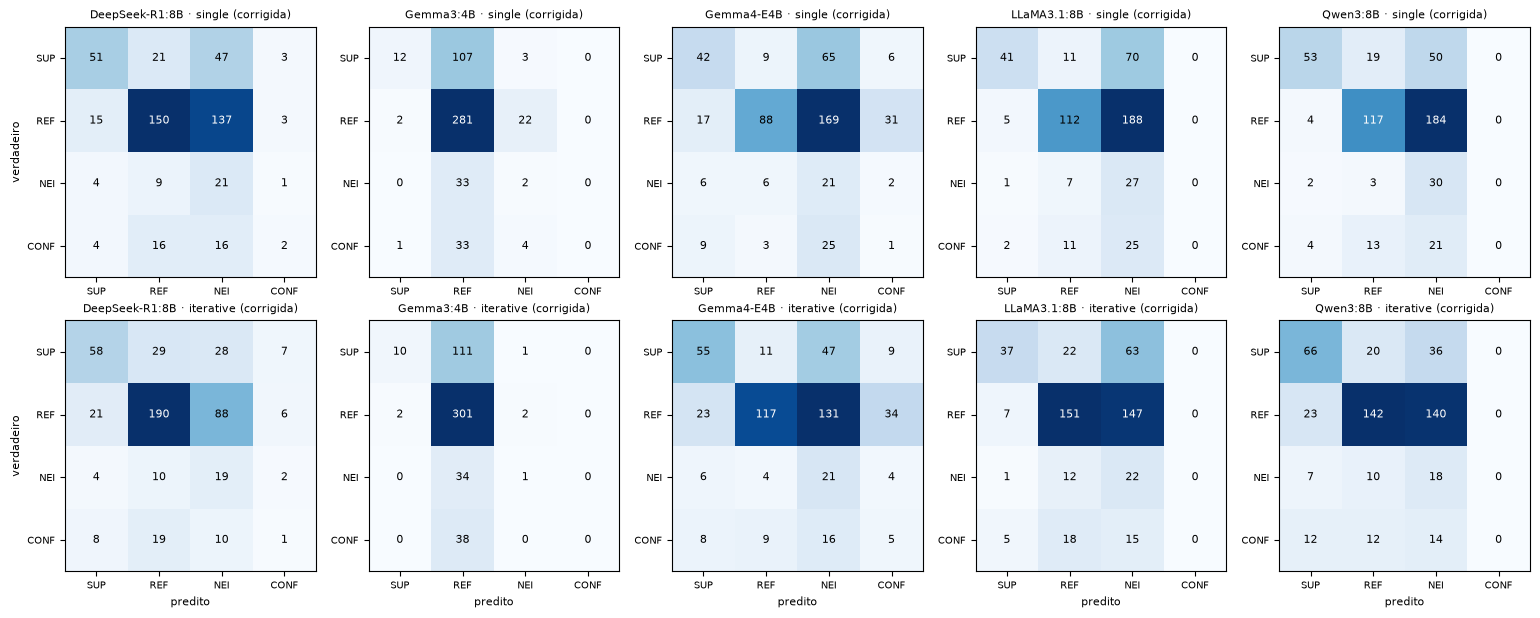

In [15]:
rows = []
for m in HF:
    for k in DIR:
        c = collections.Counter(fx[(m, k)]["pred"]); c0 = collections.Counter(hf[(m, k)]["pred"])
        rows.append([NAME[m], k] + [f"{c.get(x, 0)} ({c.get(x, 0) - c0.get(x, 0):+d})" for x in CLS])
display(Markdown("Contagens com a leitura correta; entre parênteses, a diferença para a §5 (regra original)."))
display(pd.DataFrame(rows, columns=["Modelo", "Método"] + CLS).set_index(["Modelo", "Método"]))

fig, axes = plt.subplots(2, len(HF), figsize=(3.1 * len(HF), 6.2))
for j, m in enumerate(HF):
    for i, k in enumerate(["single", "iterative"]):
        ax = axes[i, j]; M = cm(fx[(m, k)]["pred"], fx[(m, k)]["gold"])
        ax.imshow(M, cmap="Blues", vmin=0, vmax=M.max())
        for a in range(4):
            for b in range(4):
                ax.text(b, a, f"{int(M[a,b])}", ha="center", va="center", fontsize=8, color="white" if M[a, b] > .6 * M.max() else "black")
        ax.set_xticks(range(4)); ax.set_xticklabels(CLS, fontsize=7); ax.set_yticks(range(4)); ax.set_yticklabels(CLS, fontsize=7)
        ax.set_title(f"{NAME[m]} · {k} (corrigida)", fontsize=8)
        if j == 0: ax.set_ylabel("verdadeiro", fontsize=8)
        if i == 1: ax.set_xlabel("predito", fontsize=8)
plt.tight_layout(); plt.show()